<p><a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a></p>

<p><a href="https://query.farm/vgi/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/vgi-logo.png" alt="VGI" width="112"></a></p>

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Query-farm/vgi-asn1/blob/main/notebooks/01_same_values_different_bytes.ipynb)

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/) · [Example notes](https://github.com/Query-farm/vgi-asn1/blob/main/notebooks/README.md)


# Same values, different bytes

When can ASN.1 packets be grouped by their encoding, and when do their decoded values tell a different story? We inspect seven **synthetic** packets, quarantine malformed input, then compare raw bytes with the worker’s structural normalization. No certificate, key or captured network traffic is used.

All decoding and re-encoding runs through the real **vgi-asn1 v0.4.0** release. The example includes a deliberate limit: the normalizer rewrites length framing but preserves primitive payload bytes. A stable hash therefore identifies normalized bytes, not every semantically equivalent ASN.1 value.

## One controlled change

The default keeps the indefinite-length packet intact. Set `TRIM_BYTES = 1` for the closing experiment, restart the kernel and run all cells. Accepted values are integers from 0 to 3; trimming removes bytes from **only that one packet’s tail**, not from the other fixtures.

In [1]:
TRIM_BYTES = 0  # bytes removed from the indefinite-length packet; integer 0..3

In [2]:
import importlib.metadata as packages
import sys

installed = {d.metadata["Name"]: d.version for d in packages.distributions()}
if installed.get("vgi-example-notebooks") != "0.3.5":
    %pip install -q "git+https://github.com/Query-farm/vgi-example-notebooks@v0.3.5"
    if "vgi_notebooks" in sys.modules:
        raise RuntimeError("Restart the session after updating the example tools, then run all.")

In [3]:
from vgi_notebooks import check_runtime, connect, prepare, theme, prose
from IPython.display import display

check_runtime()
prepare("asn1")
import asn1_example as example  # noqa: E402

session = connect(globals())
theme()
if type(TRIM_BYTES) is not int or not 0 <= TRIM_BYTES <= 3:
    raise ValueError("TRIM_BYTES must be an integer from 0 to 3.")
byte_unit = "byte" if TRIM_BYTES == 1 else "bytes"

## Connect to the pinned release

Haybarn downloads the platform binary from the public release. This needs internet access on the first run and no Rust compiler or worker checkout. The [companion README](README.md) gives the locked environment and execution commands.

In [4]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'asn1' (TYPE vgi, LOCATION 'github-auto://Query-farm/vgi-asn1@v0.4.0');

,Success


## Build the packet collection

The first five rows describe a short SEQUENCE containing an INTEGER, an object identifier and the string `hi`. The first four decode to the same values. The fifth changes the integer from 5 to 6. The remaining rows add a short unknown OID and an intentionally broken length declaration. The shapes adapt the project’s [generic SQL tests](https://github.com/Query-farm/vgi-asn1/blob/8b74352216a08b78b04fbb0e71e022e748adca8d/test/sql/generic.test); all bytes are shown here.

The OID is just an identifier in this invented message. Its presence does not make the packet a signature or establish authenticity.

In [5]:
%%sql
CREATE TABLE packets AS
WITH fixture(id, label, hex_text) AS (
    VALUES
    (1, 'Minimal lengths / integer 5', '301202010506092a864886f70d01010b0c026869'),
    (2, 'Indefinite length / integer 5', '308002010506092a864886f70d01010b0c0268690000'),
    (3, 'Long length / integer 5', '30811202010506092a864886f70d01010b0c026869'),
    (4, 'Padded INTEGER / integer 5', '30130202000506092a864886f70d01010b0c026869'),
    (5, 'Minimal lengths / integer 6', '301202010606092a864886f70d01010b0c026869'),
    (6, 'Broken length declaration', '300502'),
    (7, 'Unknown OID', '300606042a030405')
)
SELECT id, label,
       from_hex(CASE WHEN id = 2
           THEN substring(hex_text, 1, length(hex_text) - 2 * {{TRIM_BYTES}})
           ELSE hex_text END) AS payload
FROM fixture;

SELECT label, octet_length(payload) AS raw_bytes, hex(payload) AS hexadecimal
FROM packets ORDER BY id;

,label,raw_bytes,hexadecimal
0,Minimal lengths / integer 5,20,301202010506092A864886F70D01010B0C026869
1,Indefinite length / integer 5,22,308002010506092A864886F70D01010B0C0268690000
2,Long length / integer 5,21,30811202010506092A864886F70D01010B0C026869
3,Padded INTEGER / integer 5,21,30130202000506092A864886F70D01010B0C026869
4,Minimal lengths / integer 6,20,301202010606092A864886F70D01010B0C026869
5,Broken length declaration,3,300502
6,Unknown OID,8,300606042A030405


## Separate valid structure from unavailable results

`well_formed` parses the BER framing and returns an explicit status and error category. Materializing these responses keeps later plots from calling the worker again. The separate DER check below is this release’s **structural parser check**; it does not exhaustively validate every DER primitive encoding rule.

In [6]:
%%sql
CREATE TABLE inspected AS
SELECT *,
       asn1.main.well_formed(payload) AS diagnostic,
       asn1.main.is_valid(payload, 'der') AS der_structure,
       asn1.main.decode(payload) AS decoded,
       asn1.main.to_der(payload) AS normalized
FROM packets;

SELECT label, diagnostic.ok AS well_formed, der_structure,
       diagnostic.kind AS error_kind, diagnostic.error AS error_detail
FROM inspected ORDER BY id;

,label,well_formed,der_structure,error_kind,error_detail
0,Minimal lengths / integer 5,True,True,None,None
1,Indefinite length / integer 5,True,False,None,None
2,Long length / integer 5,True,False,None,None
3,Padded INTEGER / integer 5,True,True,None,None
4,Minimal lengths / integer 6,True,True,None,None
5,Broken length declaration,False,False,length-overflow,declared length 5 exceeds the 1 available bytes
6,Unknown OID,True,True,None,None


In [7]:
%%sql availability <<
SELECT count(*) AS packet_count,
       count(*) FILTER (WHERE diagnostic.ok) AS valid_count,
       count(*) FILTER (WHERE NOT diagnostic.ok) AS malformed_count,
       count(normalized) AS normalized_count
FROM inspected;

In [8]:
a = availability.iloc[0]
prose(
    f"With **{TRIM_BYTES} tail {byte_unit} removed**, **{int(a.valid_count)} of "
    f"{int(a.packet_count)} packets** have valid BER structure. "
    f"**{int(a.malformed_count)} malformed packet(s)** remain in the diagnostics table. "
    "Their normalization result is NULL, so a missing output cannot be mistaken for an empty packet."
)

With **0 tail bytes removed**, **6 of 7 packets** have valid BER structure. **1 malformed packet(s)** remain in the diagnostics table. Their normalization result is NULL, so a missing output cannot be mistaken for an empty packet.

## What a normalized byte length can tell us

The worker’s `to_der` function rewrites identifier and length framing and orders SET children. For this SEQUENCE fixture family, inspect whether that reduces length and preserves the decoded values. The padded INTEGER is useful because its content bytes survive the transformation.

In [9]:
%%sql lengths <<
SELECT id, label, diagnostic.ok AS well_formed,
       octet_length(payload) AS raw_bytes,
       octet_length(normalized) AS normalized_bytes,
       decoded,
       hex(normalized) AS normalized_hex
FROM inspected ORDER BY id;

In [10]:
display(lengths[["label", "raw_bytes", "normalized_bytes", "decoded"]])

,label,raw_bytes,normalized_bytes,decoded
0,Minimal lengths / integer 5,20,20,"[5,""1.2.840.113549.1.1.11"",""hi""]"
1,Indefinite length / integer 5,22,20,"[5,""1.2.840.113549.1.1.11"",""hi""]"
2,Long length / integer 5,21,20,"[5,""1.2.840.113549.1.1.11"",""hi""]"
3,Padded INTEGER / integer 5,21,21,"[5,""1.2.840.113549.1.1.11"",""hi""]"
4,Minimal lengths / integer 6,20,20,"[6,""1.2.840.113549.1.1.11"",""hi""]"
5,Broken length declaration,3,<NA>,"{""error"":""declared length 5 exceeds the 1 avai..."
6,Unknown OID,8,8,"[""1.2.3.4.5""]"


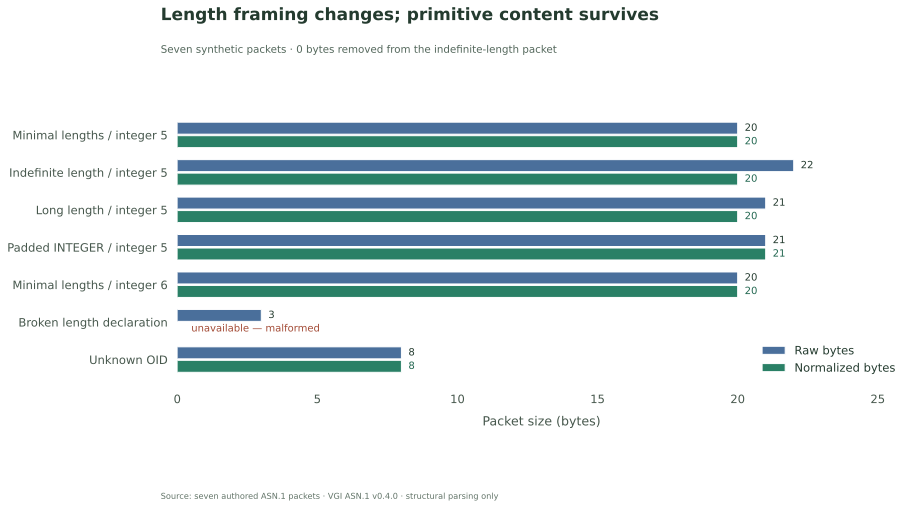

In [11]:
example.plot_lengths(lengths, TRIM_BYTES, byte_unit)

In [12]:
valid = lengths.normalized_bytes.notna()
saved_bytes = int((lengths.loc[valid, "raw_bytes"] - lengths.loc[valid, "normalized_bytes"]).sum())
padded = lengths.loc[lengths.id == 4].iloc[0]
prose(
    f"Normalization removes **{saved_bytes} {'byte' if saved_bytes == 1 else 'bytes'}** in total "
    "across the structurally valid rows. "
    f"The padded INTEGER still occupies **{int(padded.normalized_bytes)} bytes** as a complete packet. "
    "The extra integer content byte is preserved even though it decodes to the same value as the minimal form."
)

Normalization removes **3 bytes** in total across the structurally valid rows. The padded INTEGER still occupies **21 bytes** as a complete packet. The extra integer content byte is preserved even though it decodes to the same value as the minimal form.

## Group by decoded values, then count byte encodings

SQL groups the valid rows by the worker’s decoded JSON, then counts distinct byte strings before and after normalization. The raw BLOB comparisons establish distinctness; SHA-256 is displayed only as a compact fingerprint of a selected byte string. JSON equality is a practical grouping key for **these known fixtures**, not a universal ASN.1 semantic-equivalence test.

In [13]:
%%sql groups <<
SELECT decoded AS decoded_values,
       count(*) AS packets,
       count(DISTINCT payload) AS raw_encodings,
       count(DISTINCT normalized) AS normalized_encodings,
       min(sha256(normalized)) AS example_normalized_sha256
FROM inspected
WHERE diagnostic.ok
GROUP BY decoded
ORDER BY packets DESC, decoded;

In [14]:
display(groups)

,decoded_values,packets,raw_encodings,normalized_encodings,example_normalized_sha256
0,"[5,""1.2.840.113549.1.1.11"",""hi""]",4,4,2,379e036ba6e6ac50abed92f7def7a2c8d83f8bfa6ee1ef...
1,"[""1.2.3.4.5""]",1,1,1,61189d38e24982875951a6b5d3504fcaeee97b9a021226...
2,"[6,""1.2.840.113549.1.1.11"",""hi""]",1,1,1,9ebb1f53779252c0bf67345947b181c7c0046fe0657cf8...


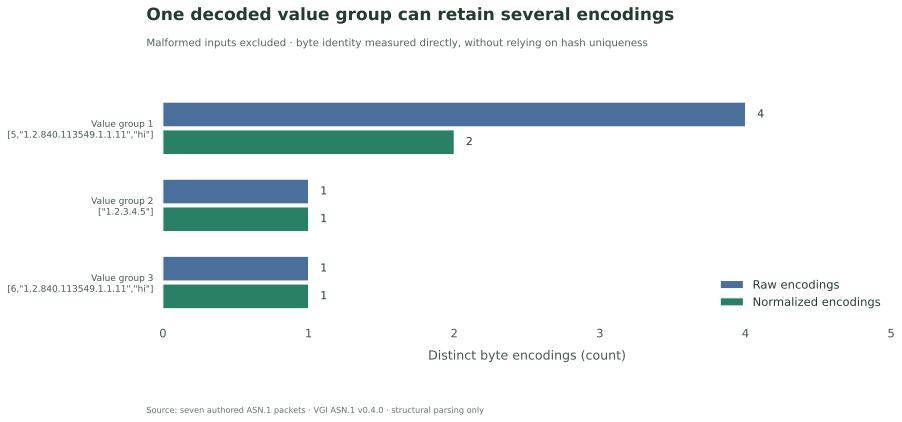

In [15]:
example.plot_groups(groups, TRIM_BYTES)

In [16]:
largest = groups.iloc[0]
prose(
    f"The largest decoded-value group contains **{int(largest.packets)} packets** and shrinks from "
    f"**{int(largest.raw_encodings)} raw encodings** to **{int(largest.normalized_encodings)} "
    "normalized encodings**. Length normalization removes framing differences, but the padded INTEGER "
    "remains distinct. This release also reports that padded packet as structurally DER-valid; "
    "do not treat that result as proof of full DER conformance. None of these operations verifies a signature."
)

The largest decoded-value group contains **4 packets** and shrinks from **4 raw encodings** to **2 normalized encodings**. Length normalization removes framing differences, but the padded INTEGER remains distinct. This release also reports that padded packet as structurally DER-valid; do not treat that result as proof of full DER conformance. None of these operations verifies a signature.

## A target label does not restore an earlier encoding

`reencode` accepts an encoding-rules argument, but this release emits its same
structurally normalized bytes for `ber`, `cer` and `der`. Compare the requested
BER result with `to_der` on the intact indefinite and padded controls. It does not
restore the indefinite framing, nor remove the padded INTEGER payload byte.
Only structurally valid inputs enter this comparison.

In [17]:
%%sql
SELECT label,hex(payload) AS original_hex,
 hex(asn1.main.reencode(payload,'ber')) AS requested_ber_hex,
 asn1.main.reencode(payload,'ber')=normalized AS same_as_to_der,
 asn1.main.reencode(payload,'der')=normalized AS explicit_der_agrees
FROM inspected WHERE id IN (2,4) AND diagnostic.ok ORDER BY id;

,label,original_hex,requested_ber_hex,same_as_to_der,explicit_der_agrees
0,Indefinite length / integer 5,308002010506092A864886F70D01010B0C0268690000,301202010506092A864886F70D01010B0C026869,True,True
1,Padded INTEGER / integer 5,30130202000506092A864886F70D01010B0C026869,30130202000506092A864886F70D01010B0C026869,True,True


The two output comparisons agree. The target spelling does not choose a distinct
wire representation in this release. Use the observed output bytes and the decoded
values to characterize normalization; a target label is not evidence of exhaustive
DER conformance.

## Inspect the structure behind the result

Unnesting the scalar `tlv` response reveals the root SEQUENCE and its children for the intact minimal packet. The root’s content length includes the child encodings; adding parent and child lengths would double-count those bytes.

In [18]:
%%sql
WITH nodes AS (
    SELECT unnest(asn1.main.tlv(payload)) AS node
    FROM inspected WHERE id = 1
)
SELECT node.path AS path, node.tag_name AS tag,
       node.constructed AS constructed, node.header_len AS header_bytes,
       node.len AS content_bytes, node.value AS interpreted_value
FROM nodes;

,path,tag,constructed,header_bytes,content_bytes,interpreted_value
0,$,SEQUENCE,True,2,18,null
1,$.0,INTEGER,False,2,1,5
2,$.1,OBJECT IDENTIFIER,False,2,9,"""1.2.840.113549.1.1.11"""
3,$.2,UTF8String,False,2,2,"""hi"""


## Check the relationships used in this analysis

These invariants apply to this collection: invalid input has no normalized bytes; valid input does; normalization is idempotent, preserves decoded values and does not increase this fixture family’s size. They do not demand a fixed row count or a particular ranking.

In [19]:
%%sql checks <<
SELECT
    count(*) FILTER (WHERE NOT diagnostic.ok AND normalized IS NOT NULL) AS invalid_with_output,
    count(*) FILTER (WHERE diagnostic.ok AND normalized IS NULL) AS valid_without_output,
    count(*) FILTER (WHERE diagnostic.ok AND
        asn1.main.to_der(normalized) IS DISTINCT FROM normalized) AS non_idempotent,
    count(*) FILTER (WHERE diagnostic.ok AND
        asn1.main.decode(normalized) IS DISTINCT FROM decoded) AS changed_values,
    count(*) FILTER (WHERE diagnostic.ok AND
        octet_length(normalized) > octet_length(payload)) AS increased_size
FROM inspected;

In [20]:
display(checks)
assert (checks.iloc[0] == 0).all(), "A relationship used in the analysis failed."
prose("All five relationships hold for this run.")

,invalid_with_output,valid_without_output,non_idempotent,changed_values,increased_size
0,0,0,0,0,0


All five relationships hold for this run.

## Experiment: remove the final terminator byte

Change **`TRIM_BYTES` from 0 to 1**, restart and run all. Predict that the indefinite-length packet will become malformed because its end-of-content marker is incomplete. Compare the error category, the number of valid packets and the first group’s raw-versus-normalized counts.

The other packets are unchanged, so this isolates the effect of one truncated frame. It does not model a realistic corruption rate or prove that every damaged packet can be detected. Reset **`TRIM_BYTES = 0`** to restore the complete packet. The runner can save this experiment to a separate directory without replacing the successful default.

In [21]:
session.close()

<a href="https://query.farm/"><img src="https://raw.githubusercontent.com/Query-farm/vgi-example-notebooks/v0.1.1/assets/query-farm-strata-sun.svg" alt="Query.Farm — Strata Sun" width="252"></a>

[Query.Farm](https://query.farm/) · [VGI](https://query.farm/vgi/)
